# Week 5 — Policy Gradient: REINFORCE, REINFORCE with Baseline, One-step Actor-Critic

This notebook implements the three policy-gradient algorithms from Sutton & Barto (2nd ed.), Chapter 13,
in PyTorch, and applies each of them to five Gymnasium environments:

| Environment | Action space | Notes |
|---|---|---|
| `CartPole-v1` | Discrete(2) | balance a pole, +1 per step, max 500 |
| `Acrobot-v1` | Discrete(3) | swing up a two-link arm, −1 per step |
| `LunarLander-v3` | Discrete(4) | land between the flags, shaped reward |
| `InvertedPendulum-v5` | Box(1) | MuJoCo, continuous force, +1 per step, max 1000 |
| `Reacher-v5` | Box(2) | MuJoCo, move a 2-joint arm's tip to a target, 50 steps |

For every environment we produce one chart in the style of **Figure 13.2**: total reward per episode
(averaged over several independent runs) for all three algorithms.

**Policy parameterisation.** The policy $\pi(a\mid s;\theta)$ is a neural network (MLP). For discrete actions it
outputs action preferences $h(s,a;\theta)$ and uses a soft-max (Eq. 13.2). For continuous actions it outputs the
mean $\mu(s;\theta)$ of a Gaussian with a learned, state-independent $\log\sigma$ (Section 13.7).
The state-value baseline / critic $\hat v(s; \mathbf w)$ is a separate MLP.

In [ ]:
%pip install -q "gymnasium[box2d,mujoco]>=1.1" torch numpy matplotlib

In [2]:
import os
import time
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical, Normal
import gymnasium as gym
import matplotlib.pyplot as plt

torch.set_num_threads(1)  # tiny networks: one thread per run, parallelism across runs instead
print("torch", torch.__version__, "| gymnasium", gym.__version__, "| CPUs", os.cpu_count())

torch 2.15.0 | gymnasium 1.4.0 | CPUs 6


## Experiment configuration

Each environment gets its own discount, episode budget, step sizes and network width.
`lr_pi` is $\alpha^\theta$ and `lr_v` is $\alpha^{\mathbf w}$ in the book's notation.
Both REINFORCE variants share the same step sizes. One-step Actor-Critic updates after *every* step rather than
once per episode, so it gets its own, smaller step sizes (`ac_lr_*`, chosen by a small sweep over 3 seeds);
with the REINFORCE step sizes its policy collapsed to a deterministic, bad policy on CartPole, Acrobot and InvertedPendulum.

In [3]:
QUICK = os.environ.get("PG_QUICK", "0") == "1"   # set PG_QUICK=1 for a fast smoke test
N_SEEDS = 2 if QUICK else 5

# lr_pi / lr_v are used by both REINFORCE variants; ac_lr_pi / ac_lr_v by one-step Actor-Critic, which updates
# after every step (hundreds of updates per episode instead of one) and diverges with the REINFORCE step sizes.
ENV_CONFIGS = {
    "CartPole-v1":         dict(episodes=1000, gamma=0.99, lr_pi=1e-3, lr_v=3e-3, ac_lr_pi=1e-4, ac_lr_v=1e-3, hidden=64),
    "Acrobot-v1":          dict(episodes=500,  gamma=0.99, lr_pi=1e-3, lr_v=3e-3, ac_lr_pi=3e-4, ac_lr_v=1e-3, hidden=64),
    "LunarLander-v3":      dict(episodes=2000, gamma=0.99, lr_pi=5e-4, lr_v=1e-3, ac_lr_pi=5e-4, ac_lr_v=1e-3, hidden=128),
    "InvertedPendulum-v5": dict(episodes=1000, gamma=0.99, lr_pi=1e-3, lr_v=3e-3, ac_lr_pi=1e-4, ac_lr_v=1e-3, hidden=64),
    "Reacher-v5":          dict(episodes=2000, gamma=0.99, lr_pi=1e-3, lr_v=3e-3, ac_lr_pi=3e-4, ac_lr_v=1e-3, hidden=64),
}
if QUICK:
    for c in ENV_CONFIGS.values():
        c["episodes"] = max(50, c["episodes"] // 10)

ALGOS = ["REINFORCE", "REINFORCE with baseline", "Actor-Critic"]
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

## Function approximators

* `Policy` — returns a `torch.distributions` object for a batch of states, so the same code handles
  discrete (soft-max over preferences) and continuous (Gaussian) actions.
* `ValueNet` — the state-value function $\hat v(s;\mathbf w)$.

In [4]:
def mlp(inp, out, hidden):
    return nn.Sequential(
        nn.Linear(inp, hidden), nn.Tanh(),
        nn.Linear(hidden, hidden), nn.Tanh(),
        nn.Linear(hidden, out),
    )


class Policy(nn.Module):
    def __init__(self, obs_dim, action_space, hidden):
        super().__init__()
        self.discrete = isinstance(action_space, gym.spaces.Discrete)
        if self.discrete:
            self.net = mlp(obs_dim, action_space.n, hidden)          # action preferences h(s,a,θ)
        else:
            act_dim = action_space.shape[0]
            self.net = mlp(obs_dim, act_dim, hidden)                 # Gaussian mean μ(s,θ)
            self.log_std = nn.Parameter(torch.zeros(act_dim))        # learned log σ
            self.register_buffer("scale", torch.as_tensor((action_space.high - action_space.low) / 2, dtype=torch.float32))
            self.register_buffer("center", torch.as_tensor((action_space.high + action_space.low) / 2, dtype=torch.float32))

    def dist(self, s):
        out = self.net(s)
        if self.discrete:
            return Categorical(logits=out)                            # soft-max in action preferences (Eq. 13.2)
        mean = self.center + self.scale * torch.tanh(out)
        std = self.scale * self.log_std.exp()
        return Normal(mean, std)

    def log_prob(self, dist, a):
        lp = dist.log_prob(a)
        return lp if self.discrete else lp.sum(-1)


class ValueNet(nn.Module):
    def __init__(self, obs_dim, hidden):
        super().__init__()
        self.net = mlp(obs_dim, 1, hidden)

    def forward(self, s):
        return self.net(s).squeeze(-1)


def to_env_action(policy, a, env):
    """Convert a sampled torch action into something env.step accepts (continuous actions are clipped)."""
    if policy.discrete:
        return int(a.item())
    return np.clip(a.numpy(), env.action_space.low, env.action_space.high)

## Algorithm 1 — REINFORCE: Monte-Carlo Policy-Gradient Control (Section 13.3)

Generate an episode $S_0,A_0,R_1,\dots,S_{T-1},A_{T-1},R_T$ following $\pi(\cdot\mid\cdot;\theta)$, then for each step

$$G \leftarrow \sum_{k=t+1}^{T}\gamma^{k-t-1}R_k, \qquad
  \theta \leftarrow \theta + \alpha\,\gamma^t\, G\, \nabla \ln \pi(A_t\mid S_t;\theta).$$

The per-step updates are accumulated into one gradient step at the end of the episode (the loss below is the
negative of the summed update direction). We use Adam instead of plain SGD for the step size.

In [5]:
def discounted_returns(rewards, gamma):
    G, out = 0.0, np.zeros(len(rewards), dtype=np.float32)
    for t in reversed(range(len(rewards))):
        G = rewards[t] + gamma * G
        out[t] = G
    return out


def generate_episode(env, policy):
    states, actions, rewards = [], [], []
    s, _ = env.reset()
    done = False
    while not done:
        st = torch.as_tensor(s, dtype=torch.float32)
        with torch.no_grad():
            a = policy.dist(st).sample()
        s2, r, terminated, truncated, _ = env.step(to_env_action(policy, a, env))
        states.append(st); actions.append(a); rewards.append(float(r))
        s, done = s2, terminated or truncated
    return torch.stack(states), torch.stack(actions), rewards


def reinforce(env, cfg, n_episodes, baseline=False):
    obs_dim = env.observation_space.shape[0]
    gamma = cfg["gamma"]
    policy = Policy(obs_dim, env.action_space, cfg["hidden"])
    opt_pi = torch.optim.Adam(policy.parameters(), lr=cfg["lr_pi"])
    if baseline:
        v = ValueNet(obs_dim, cfg["hidden"])
        opt_v = torch.optim.Adam(v.parameters(), lr=cfg["lr_v"])

    ep_returns = np.zeros(n_episodes, dtype=np.float32)
    for ep in range(n_episodes):
        S, A, R = generate_episode(env, policy)
        T = len(R)
        G = torch.as_tensor(discounted_returns(R, gamma))
        disc = torch.as_tensor(gamma ** np.arange(T), dtype=torch.float32)   # γ^t
        logp = policy.log_prob(policy.dist(S), A)

        if baseline:
            # Algorithm 2 — δ ← G − v̂(S_t,w);  w ← w + α^w δ ∇v̂;  θ ← θ + α^θ γ^t δ ∇ln π
            values = v(S)
            delta = G - values
            loss_v = 0.5 * (delta ** 2).sum()           # ∇_w of this = −δ ∇v̂  ⇒ descent = the book's update
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
            weight = delta.detach()
        else:
            weight = G

        loss_pi = -(disc * weight * logp).sum()
        opt_pi.zero_grad(); loss_pi.backward(); opt_pi.step()
        ep_returns[ep] = sum(R)
    return ep_returns

## Algorithm 2 — REINFORCE with Baseline (Section 13.4)

Same as REINFORCE, but a learned state-value function $\hat v(S_t;\mathbf w)$ is subtracted from the return:

$$\delta \leftarrow G - \hat v(S_t;\mathbf w),\qquad
  \mathbf w \leftarrow \mathbf w + \alpha^{\mathbf w}\,\delta\,\nabla \hat v(S_t;\mathbf w),\qquad
  \theta \leftarrow \theta + \alpha^{\theta}\,\gamma^t\,\delta\,\nabla \ln\pi(A_t\mid S_t;\theta).$$

This is `reinforce(..., baseline=True)` above. The baseline does not change the expected update but reduces its variance.

## Algorithm 3 — One-step Actor-Critic (episodic) (Section 13.5)

Fully online: after **every** step,

$$\delta \leftarrow R + \gamma\,\hat v(S';\mathbf w) - \hat v(S;\mathbf w)\quad(\hat v(S')=0 \text{ if } S' \text{ is terminal}),$$
$$\mathbf w \leftarrow \mathbf w + \alpha^{\mathbf w}\,\delta\,\nabla\hat v(S;\mathbf w),\qquad
  \theta \leftarrow \theta + \alpha^{\theta}\, I\,\delta\,\nabla\ln\pi(A\mid S;\theta),\qquad I \leftarrow \gamma I.$$

Only a true **termination** zeroes $\hat v(S')$; a time-limit **truncation** still bootstraps from $\hat v(S')$.

In [6]:
def actor_critic(env, cfg, n_episodes):
    obs_dim = env.observation_space.shape[0]
    gamma = cfg["gamma"]
    policy = Policy(obs_dim, env.action_space, cfg["hidden"])
    v = ValueNet(obs_dim, cfg["hidden"])
    opt_pi = torch.optim.Adam(policy.parameters(), lr=cfg["lr_pi"])
    opt_v = torch.optim.Adam(v.parameters(), lr=cfg["lr_v"])

    ep_returns = np.zeros(n_episodes, dtype=np.float32)
    for ep in range(n_episodes):
        s, _ = env.reset()
        st = torch.as_tensor(s, dtype=torch.float32)
        I, total, done = 1.0, 0.0, False
        while not done:
            dist = policy.dist(st)
            a = dist.sample()
            s2, r, terminated, truncated, _ = env.step(to_env_action(policy, a, env))
            s2t = torch.as_tensor(s2, dtype=torch.float32)

            with torch.no_grad():
                v_next = 0.0 if terminated else v(s2t)
            v_s = v(st)
            delta = r + gamma * v_next - v_s

            loss_v = 0.5 * delta ** 2
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()

            loss_pi = -I * delta.detach() * policy.log_prob(dist, a)
            opt_pi.zero_grad(); loss_pi.backward(); opt_pi.step()

            I *= gamma
            total += r
            st, done = s2t, terminated or truncated
        ep_returns[ep] = total
    return ep_returns

## Running the experiments

One *run* = one (environment, algorithm, seed) triple trained from scratch. Runs are independent, so we
execute them in parallel across CPU cores. Results are cached to `results/` as `.npy` arrays of shape
`(n_seeds, n_episodes)`, so re-running the notebook only trains what is missing.

In [7]:
def run_one(env_id, algo, seed, overrides=None):
    torch.set_num_threads(1)
    cfg = {**ENV_CONFIGS.get(env_id, {}), **(overrides or {})}
    if algo == "Actor-Critic":   # one-step AC makes an update every step -> its own (smaller) step sizes
        cfg = {**cfg, "lr_pi": cfg.get("ac_lr_pi", cfg["lr_pi"]), "lr_v": cfg.get("ac_lr_v", cfg["lr_v"])}
    torch.manual_seed(seed); np.random.seed(seed)
    env = gym.make(env_id)
    env.reset(seed=seed); env.action_space.seed(seed)
    t0 = time.time()
    if algo == "REINFORCE":
        r = reinforce(env, cfg, cfg["episodes"], baseline=False)
    elif algo == "REINFORCE with baseline":
        r = reinforce(env, cfg, cfg["episodes"], baseline=True)
    else:
        r = actor_critic(env, cfg, cfg["episodes"])
    env.close()
    return env_id, algo, seed, r, time.time() - t0


def result_path(env_id, algo):
    tag = "quick_" if QUICK else ""
    return os.path.join(RESULTS_DIR, f"{tag}{env_id}__{algo.replace(' ', '_')}.npy")


def run_all(env_ids=None, workers=None):
    env_ids = env_ids or list(ENV_CONFIGS)
    jobs = [(e, a, s) for e in env_ids for a in ALGOS for s in range(N_SEEDS)
            if not os.path.exists(result_path(e, a))]
    print(f"{len(jobs)} runs to do")
    if not jobs:
        return
    buf = {}
    ctx = mp.get_context("fork")
    with ProcessPoolExecutor(max_workers=workers or os.cpu_count(), mp_context=ctx) as ex:
        futs = [ex.submit(run_one, *j) for j in jobs]
        for f in as_completed(futs):
            e, a, s, r, dt = f.result()
            print(f"  {e:20s} {a:24s} seed={s}  last-50 mean={r[-50:].mean():8.1f}  ({dt:5.0f}s)")
            buf.setdefault((e, a), {})[s] = r
            if len(buf[(e, a)]) == N_SEEDS:
                np.save(result_path(e, a), np.stack([buf[(e, a)][k] for k in range(N_SEEDS)]))

In [8]:
if __name__ == "__main__":
    t0 = time.time()
    run_all()
    print(f"total {time.time() - t0:.0f}s")

0 runs to do
total 0s


## Results — one chart per environment (cf. Figure 13.2)

Solid line: mean total reward per episode over the independent runs (smoothed with a moving average for
readability); shaded band: ± one standard deviation across runs.

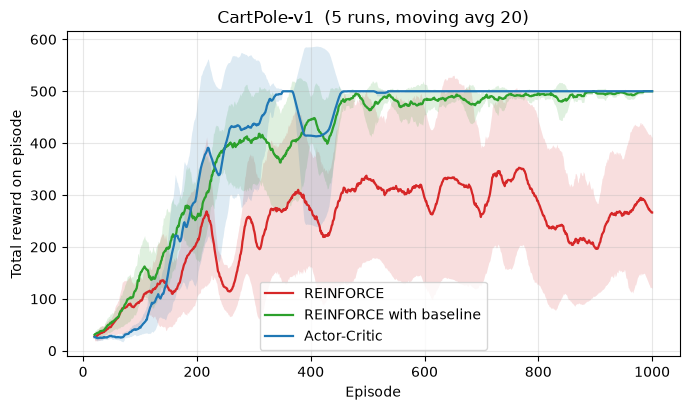

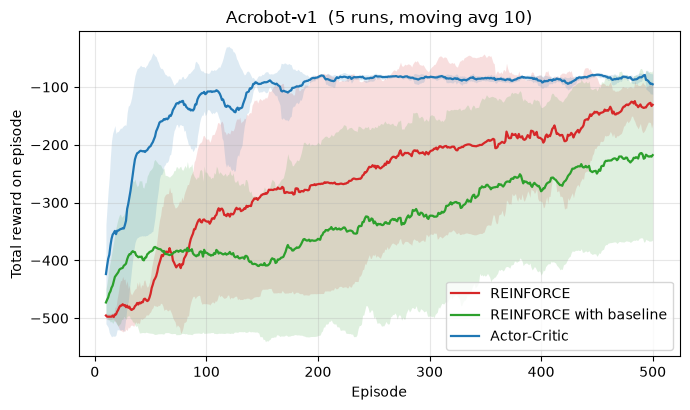

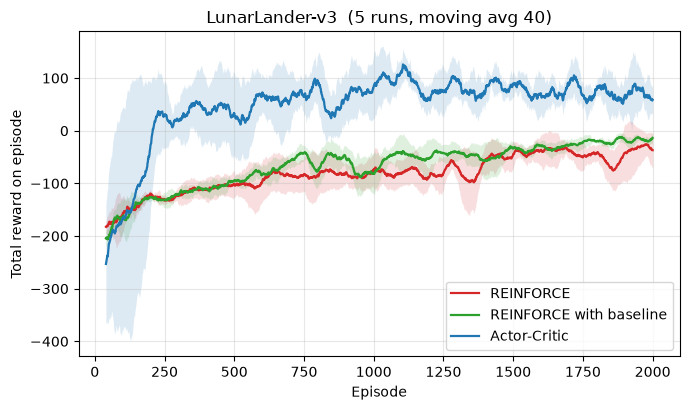

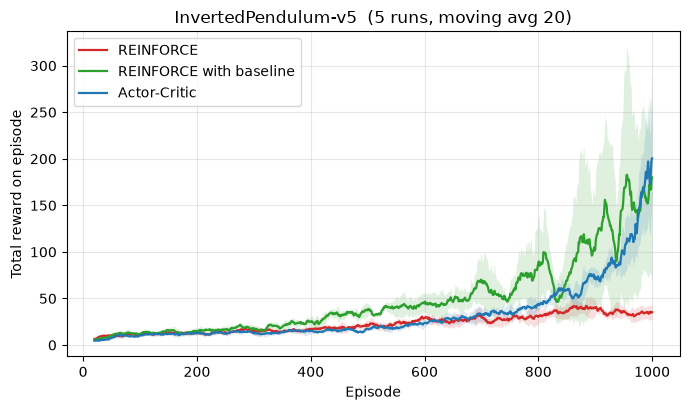

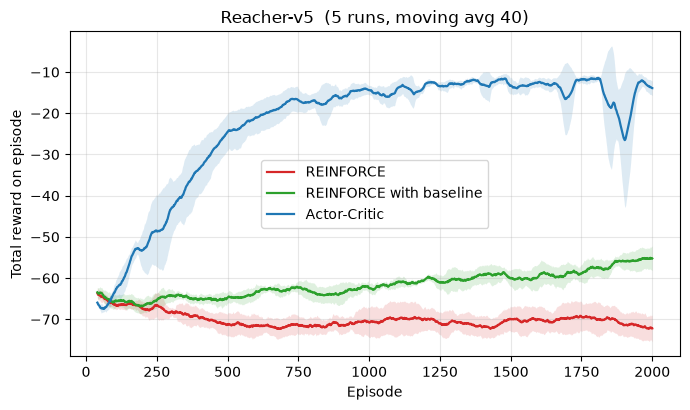

In [9]:
def smooth(x, w):
    if w <= 1:
        return x
    k = np.ones(w) / w
    return np.array([np.convolve(row, k, mode="valid") for row in np.atleast_2d(x)])


COLORS = {"REINFORCE": "#d62728", "REINFORCE with baseline": "#2ca02c", "Actor-Critic": "#1f77b4"}


def plot_env(env_id, window=None, save=True):
    n_ep = ENV_CONFIGS[env_id]["episodes"]
    window = window or max(1, n_ep // 50)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for algo in ALGOS:
        p = result_path(env_id, algo)
        if not os.path.exists(p):
            continue
        data = smooth(np.load(p), window)
        mean, std = data.mean(0), data.std(0)
        x = np.arange(window, n_ep + 1)
        ax.plot(x, mean, color=COLORS[algo], label=algo, lw=1.6)
        ax.fill_between(x, mean - std, mean + std, color=COLORS[algo], alpha=0.15, lw=0)
    ax.set_title(f"{env_id}  ({N_SEEDS} runs, moving avg {window})")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Total reward on episode")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    if save:
        fig.savefig(os.path.join(RESULTS_DIR, f"{'quick_' if QUICK else ''}{env_id}.png"), dpi=130)
    return fig


if __name__ == "__main__":
    for env_id in ENV_CONFIGS:
        plot_env(env_id)
    plt.show()

## Discussion

Mean total reward over the **last 50 episodes** (5 runs each):

| Environment | REINFORCE | REINFORCE w/ baseline | Actor-Critic |
|---|---|---|---|
| CartPole-v1 (max 500) | 278 | 498 | **500** |
| Acrobot-v1 (best ≈ −60) | −136 | −222 | **−86** |
| LunarLander-v3 (solved ≥ 200) | −35 | −16 | **62** |
| InvertedPendulum-v5 (max 1000) | 34 | 161 | **166** |
| Reacher-v5 (best ≈ −4) | −72 | −55 | **−14** |

**Baseline vs. no baseline (the Figure 13.2 comparison).** On 4 of 5 environments the baseline clearly helps:
on CartPole every baseline run reaches ≈500 while plain REINFORCE ends anywhere between 147 and 500 (very wide band);
on InvertedPendulum and Reacher plain REINFORCE barely improves while the baseline version keeps climbing.
This is exactly the variance-reduction argument of Section 13.4: subtracting $\hat v(S_t)$ leaves the expected
update unchanged but removes the part of $G_t$ that is the same for every action, so the gradient estimate is far less noisy.
**Acrobot is the exception**: one baseline run never escaped the −500 plateau (it never reached the goal, so every return
is the same and $\delta = G - \hat v$ goes to 0 once the critic fits it — there is no learning signal), which drags the mean down.
This shows a weakness of the baseline: under sparse rewards it can quickly cancel the (already small) signal.

**Actor-Critic.** Bootstrapping from $\hat v(S')$ replaces the full Monte-Carlo return with a one-step TD target, which
has much lower variance and lets the agent learn **during** the episode. It is the fastest learner everywhere and the
best final performer on every environment — most visibly on LunarLander and Reacher, where both REINFORCE variants
are still slowly improving after 2000 episodes. The price is bias from the critic and sensitivity to step size:
with the same step sizes as REINFORCE it collapsed to a deterministic, bad policy on three environments, and
it only became stable with 3–10× smaller policy step sizes (it makes one update per *step*, not per episode).
On InvertedPendulum it starts slower than the baseline method and only catches up at the end.

**The $\gamma^t$ / $I$ factor.** Following the book exactly, the update at step $t$ is scaled by $\gamma^t$. In long episodes
(CartPole up to 500 steps, InvertedPendulum up to 1000) $0.99^{500}\approx 0.007$, so the later part of an episode
contributes almost nothing to learning. This is one reason InvertedPendulum learns so slowly for all three methods,
and why practical implementations usually drop this factor.

**Implementation notes / deviations from the book.** (1) Adam is used instead of plain SGD. (2) In both REINFORCE variants
the per-step updates of an episode are summed into a single gradient step at the end of the episode (the book applies
them one after another with the same, already-fixed episode). (3) For time-limit truncation, Actor-Critic still
bootstraps from $\hat v(S')$; only true termination sets $\hat v(S')=0$.